# Dynamic hierarchical points model: evaluation and live-state monitoring

The model separates immediately observable role and context from a slowly changing player state:

\[
a_{i,t}=a_{i,t-1}+\epsilon_{i,t}, \qquad
y_{i,t}=x_{i,t}^{\mathsf T}\beta+\alpha_{\mathrm{position}}+\alpha_{\mathrm{team}}+a_{i,t}+\eta_{i,t}.
\]

Minutes, shot volume, rest, opponent defense, home court, position, and team determine the shared pregame component. A Kalman update moves the latent state only after a completed game's points are observed. The configured 0.35-point game drift and 2.0-point offseason drift are explicit assumptions, not values selected on an evaluation season.

**Status and leakage contract.** Each walk-forward fold fits on the two complete seasons immediately preceding its evaluation season. Lagged role features, opponent defense, and player state use only information available before each game; the current game's points enter only the postgame state update. Fold audits and causal assertions below make that contract visible.

**Two distinct outputs.** The multi-season walk-forward trace is an out-of-sample evaluation. The final section rebuilds the latest-season state causally from the latest two complete prior seasons and shows each player's most recently updated state. It is monitoring of observed live state, **not a future-game forecast**: no future schedule, opponent, or role row is supplied.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
if not (ROOT / "pyproject.toml").exists():
    raise RuntimeError("run this notebook from inside the nba_quant repository")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.models.dynamic_points import (
    DynamicPointsConfig,
    build_causal_frame,
    walk_forward_trace,
)
from src.models.dynamic_points_diagnostics import (
    core_calibration,
    gain_summary,
    group_calibration,
    offseason_summary,
    posterior_draw_summary,
    shrinkage_summary,
    variance_decomposition,
)

sns.set_theme(style="whitegrid")
CONFIG = DynamicPointsConfig(
    state_drift_sd=0.35,
    offseason_drift_sd=2.0,
    train_window_seasons=2,
    min_group_n=30,
)
SEASON_PATHS = sorted(
    ROOT.glob("data/silver/nba/*/regular_season/player_gamelogs.parquet")
)
if len(SEASON_PATHS) < CONFIG.train_window_seasons + 1:
    raise ValueError("need at least three complete season parquet files")

print(f"Repository root: {ROOT}")
print(f"Discovered {len(SEASON_PATHS)} season files")

Repository root: /Users/alexgonzalez/Documents/nba_quant
Discovered 8 season files


In [2]:
season_frames = []
raw_rows = 0
for season_path in SEASON_PATHS:
    season = pd.read_parquet(season_path)
    raw_rows += len(season)
    season = season.loc[season["season_type"].eq("Regular Season")].copy()
    season_frames.append(season)

games = pd.concat(season_frames, ignore_index=True)
missing_position_rows = int(games["pos"].isna().sum())
games["pos"] = games["pos"].fillna("UNK").astype(str)
print(
    f"Loaded {raw_rows:,} rows; retained {len(games):,} regular-season rows "
    f"from {len(SEASON_PATHS)} files."
)
print(
    f"Normalized {missing_position_rows:,} missing position values to the "
    "explicit 'UNK' category; no rows were dropped."
)

causal, causal_audit = build_causal_frame(games)
print("Causal-frame audit:")
display(pd.DataFrame([causal_audit]))

available_seasons = sorted(
    causal["season_year"].astype(str).unique(),
    key=lambda value: int(value.split("-")[0]),
)
evaluation_seasons = tuple(available_seasons[CONFIG.train_window_seasons :])
trace, fold_audits = walk_forward_trace(
    causal,
    evaluation_seasons=evaluation_seasons,
    config=CONFIG,
)
fold_audit_table = pd.DataFrame(fold_audits)
print("Walk-forward fold audits (every evaluation fold):")
display(fold_audit_table)

if trace.empty:
    raise AssertionError("walk-forward evaluation trace must not be empty")
numeric_trace = trace.select_dtypes(include="number")
if numeric_trace.empty or not np.isfinite(numeric_trace.to_numpy(dtype=float)).all():
    raise AssertionError("numeric diagnostic columns must be finite")
trace_key = ["season_year", "player_id", "game_id"]
if trace.duplicated(trace_key).any():
    raise AssertionError("trace must contain one row per player/game/fold")
if set(trace["season_year"].unique()) != set(evaluation_seasons):
    raise AssertionError("every requested evaluation season must appear in the trace")
print(
    f"Validated {len(trace):,} causal predictions across "
    f"{len(evaluation_seasons)} evaluation seasons: {', '.join(evaluation_seasons)}"
)

Loaded 178,013 rows; retained 178,013 regular-season rows from 8 files.
Normalized 228 missing position values to the explicit 'UNK' category; no rows were dropped.


Causal-frame audit:


,input_rows,non_regular_season_rows_removed,nonpositive_minute_rows_removed,missing_minute_rows_removed,output_rows,minutes_missing_values,fga_missing_values,fta_missing_values,team_def_rating_missing_values
0,178013,0,13,0,178000,0,0,0,0


Walk-forward fold audits (every evaluation fold):


,train_seasons,evaluation_season,candidate_rows,fitted_rows,zero_minute_rows_removed,imputed_feature_cells,predicted_rows,evaluation_imputed_feature_cells,evaluation_rows_with_imputation
0,"(2019-20, 2020-21)",2021-22,45446,45446,0,3955,26036,1028,605
1,"(2020-21, 2021-22)",2022-23,49090,49090,0,1883,25892,800,539
2,"(2021-22, 2022-23)",2023-24,51928,51928,0,1828,26399,875,572
3,"(2022-23, 2023-24)",2024-25,52291,52291,0,1675,26303,884,569
4,"(2023-24, 2024-25)",2025-26,52702,52702,0,1759,26649,894,582
5,"(2024-25, 2025-26)",2026-27,52952,52952,0,1778,1275,558,417


Validated 132,554 causal predictions across 6 evaluation seasons: 2021-22, 2022-23, 2023-24, 2024-25, 2025-26, 2026-27


Core calibration:


,n,seasons,mean_z,sd_z,rmse,mae,coverage_50,coverage_80,coverage_90,coverage_95
0,132554,"(2021-22, 2022-23, 2023-24, 2024-25, 2025-26, ...",-0.006725,0.965812,6.056612,4.632615,0.561854,0.837055,0.914925,0.95174


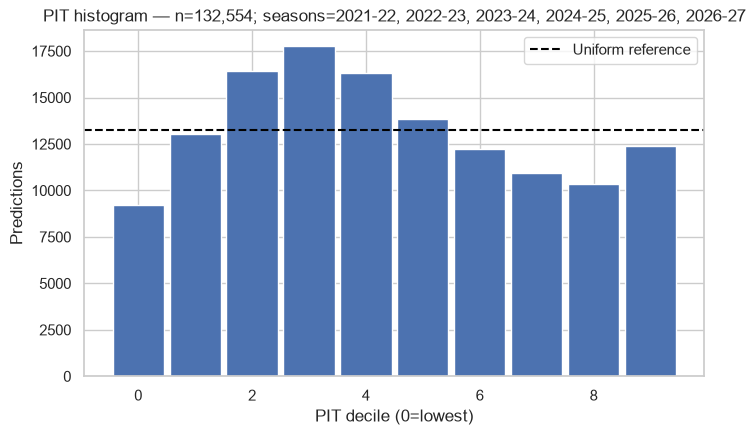

Variance decomposition and coverage by games-in-model tier:


,games_tier,n,state_plugin_scale_squared_share,observation_plugin_scale_squared_share,mean_z,sd_z,coverage_50,coverage_80,coverage_90,coverage_95
0,60+,107931,0.066498,0.933502,0.005149,0.994451,0.545247,0.824972,0.906857,0.946790
1,30-59,11449,0.070312,0.929688,0.027662,0.846460,0.630710,0.886366,0.941742,0.967421
2,10-29,8094,0.069984,0.930016,-0.029496,0.804965,0.658389,0.901038,0.952063,0.975290
3,0-9,5080,0.081393,0.918607,-0.300226,0.767523,0.605709,0.880709,0.966732,0.984055


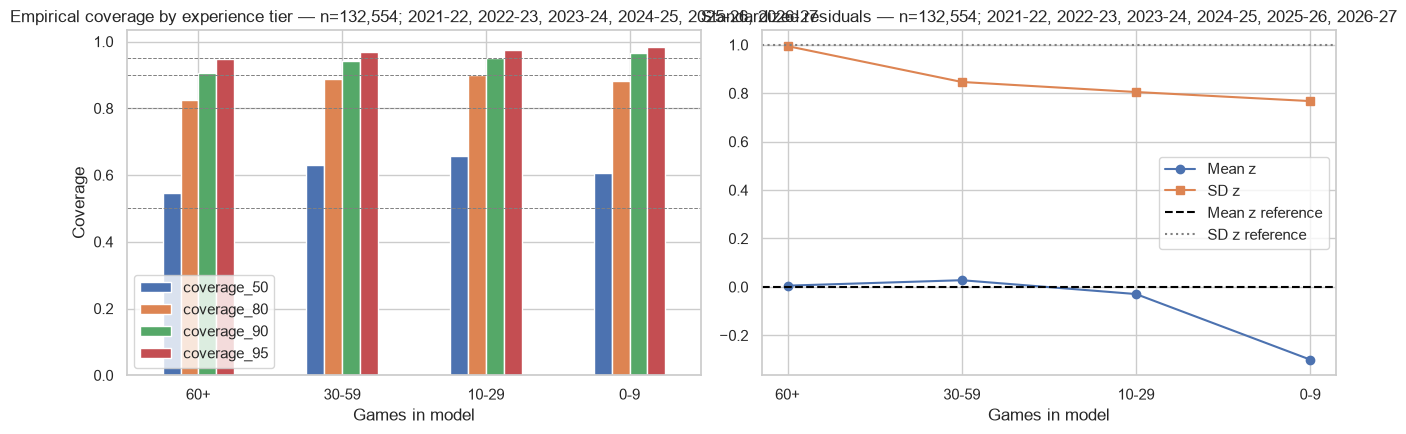

In [3]:
core = core_calibration(trace)
core_table = pd.DataFrame(
    [{key: value for key, value in core.items() if key != "pit_histogram"}]
)
print("Core calibration:")
display(core_table)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(np.arange(10), core["pit_histogram"], width=0.9)
ax.axhline(core["n"] / 10, color="black", linestyle="--", label="Uniform reference")
ax.set(
    title=(
        f"PIT histogram — n={core['n']:,}; "
        f"seasons={', '.join(core['seasons'])}"
    ),
    xlabel="PIT decile (0=lowest)",
    ylabel="Predictions",
)
ax.legend()
plt.show()

variance_report = variance_decomposition(trace)
print("Variance decomposition and coverage by games-in-model tier:")
display(variance_report)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
coverage_columns = ["coverage_50", "coverage_80", "coverage_90", "coverage_95"]
variance_report.set_index("games_tier")[coverage_columns].plot(kind="bar", ax=axes[0])
for level in (0.50, 0.80, 0.90, 0.95):
    axes[0].axhline(level, color="gray", linewidth=0.7, linestyle="--")
axes[0].set(
    title=f"Empirical coverage by experience tier — n={len(trace):,}; {', '.join(evaluation_seasons)}",
    ylabel="Coverage",
    xlabel="Games in model",
)
axes[0].tick_params(axis="x", rotation=0)
axes[1].plot(variance_report["games_tier"].astype(str), variance_report["mean_z"], marker="o", label="Mean z")
axes[1].plot(variance_report["games_tier"].astype(str), variance_report["sd_z"], marker="s", label="SD z")
axes[1].axhline(0, color="black", linestyle="--", label="Mean z reference")
axes[1].axhline(1, color="gray", linestyle=":", label="SD z reference")
axes[1].set(title=f"Standardized residuals — n={len(trace):,}; {', '.join(evaluation_seasons)}", xlabel="Games in model")
axes[1].legend()
plt.tight_layout()
plt.show()


Shrinkage by games-in-model tier:


,games_tier,n,mean_z,mean_innovation
0,60+,107931,0.005149,0.029424
1,30-59,11449,0.027662,0.167319
2,10-29,8094,-0.029496,-0.189222
3,0-9,5080,-0.300226,-1.903200


Shrinkage by pregame-state decile:


,state_decile,n,mean_state,mean_innovation,innovation_se,extreme_decile,toward_zero,significant,under_shrinkage_flag
0,"(-6.398000000000001, -3.176]",13256,-3.824683,0.546334,0.034916,True,True,True,True
1,"(-3.176, -2.383]",13255,-2.762731,0.317696,0.039983,False,True,True,False
2,"(-2.383, -1.707]",13255,-2.045318,0.040910,0.042789,False,True,False,False
3,"(-1.707, -1.011]",13256,-1.364265,-0.128263,0.044846,False,False,True,False
4,"(-1.011, -0.197]",13255,-0.621114,-0.095560,0.048724,False,False,False,False
5,"(-0.197, 0.796]",13255,0.261353,-0.420139,0.052301,False,True,True,False
6,"(0.796, 2.184]",13256,1.459438,-0.071303,0.054966,False,True,False,False
7,"(2.184, 4.292]",13255,3.158562,-0.078594,0.058771,False,True,False,False
8,"(4.292, 7.476]",13255,5.762175,-0.130053,0.064179,False,True,True,False
9,"(7.476, 22.64]",13256,10.914505,-0.441860,0.072456,True,True,True,True


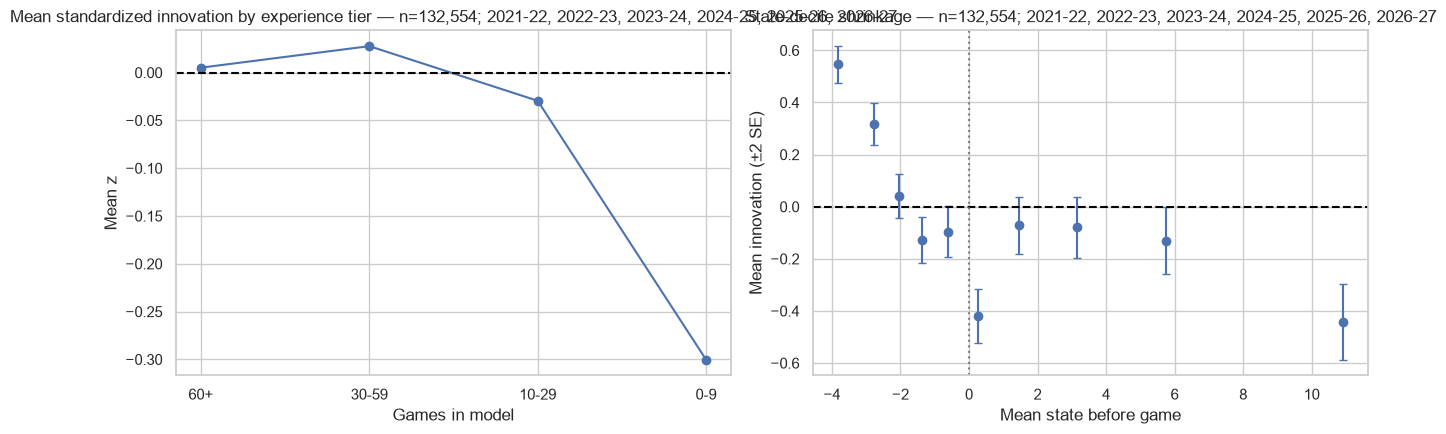

In [4]:
tier_shrinkage, state_decile_shrinkage = shrinkage_summary(trace)
print("Shrinkage by games-in-model tier:")
display(tier_shrinkage)
print("Shrinkage by pregame-state decile:")
display(state_decile_shrinkage)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(tier_shrinkage["games_tier"].astype(str), tier_shrinkage["mean_z"], marker="o")
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set(
    title=f"Mean standardized innovation by experience tier — n={len(trace):,}; {', '.join(evaluation_seasons)}",
    xlabel="Games in model",
    ylabel="Mean z",
)
axes[1].errorbar(
    state_decile_shrinkage["mean_state"],
    state_decile_shrinkage["mean_innovation"],
    yerr=2 * state_decile_shrinkage["innovation_se"],
    fmt="o",
    capsize=3,
)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].axvline(0, color="gray", linestyle=":")
axes[1].set(
    title=f"State-decile shrinkage — n={len(trace):,}; {', '.join(evaluation_seasons)}",
    xlabel="Mean state before game",
    ylabel="Mean innovation (±2 SE)",
)
plt.tight_layout()
plt.show()

Offseason calibration for all requested early windows and their complements:


,window,period,n,mean_z,sd_z,coverage_50,coverage_80,coverage_90,coverage_95
0,5,early,12489,-0.116198,0.902796,0.582993,0.849307,0.925294,0.962127
1,5,rest,103669,0.015788,0.984888,0.553666,0.830132,0.909404,0.947863
2,10,early,23224,-0.065263,0.903942,0.590510,0.854547,0.927274,0.961419
3,10,rest,92934,0.018305,0.994022,0.548400,0.826608,0.907074,0.946392
4,20,early,43361,-0.029321,0.924951,0.584927,0.850280,0.922626,0.957450
5,20,rest,72797,0.020013,1.006658,0.540077,0.821421,0.904254,0.944599


Early-season innovation/state relationship (returners, games 1-20):


,n,slope,intercept,correlation,p_value,slope_se
0,43361,-0.062599,-0.142456,-0.047331,6.136196e-23,0.006344


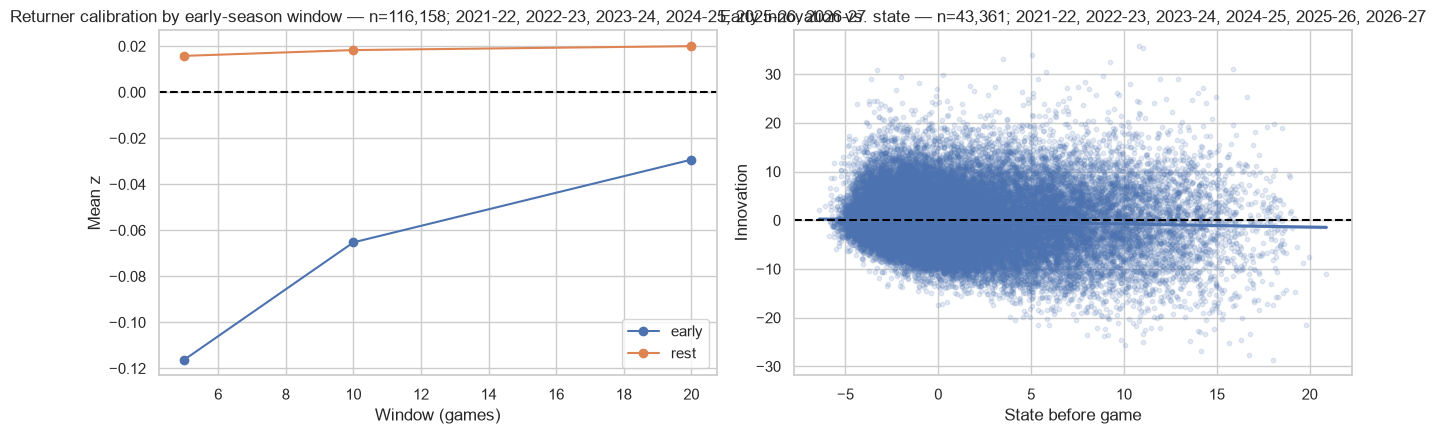

In [5]:
offseason_windows, innovation_state_relationship = offseason_summary(trace)
print("Offseason calibration for all requested early windows and their complements:")
display(offseason_windows)
print("Early-season innovation/state relationship (returners, games 1-20):")
display(pd.DataFrame([innovation_state_relationship]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for period, subset in offseason_windows.groupby("period", sort=False):
    axes[0].plot(subset["window"], subset["mean_z"], marker="o", label=period)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set(
    title=f"Returner calibration by early-season window — n={int(trace['returning_player'].sum()):,}; {', '.join(evaluation_seasons)}",
    xlabel="Window (games)",
    ylabel="Mean z",
)
axes[0].legend()
early_returners = trace.loc[trace["returning_player"] & trace["season_game_number"].le(20)]
sns.regplot(data=early_returners, x="state_before", y="innovation", scatter_kws={"alpha": 0.15, "s": 10}, ax=axes[1])
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set(
    title=f"Early innovation vs. state — n={len(early_returners):,}; {', '.join(evaluation_seasons)}",
    xlabel="State before game",
    ylabel="Innovation",
)
plt.tight_layout()
plt.show()

In [6]:
group_reports = {}
for group_column in ("opp_team_id", "team_id", "position"):
    report = group_calibration(trace, group_column, min_n=CONFIG.min_group_n)
    report = report.sort_values(
        ["actionable_flag", "low_sample", "n"],
        ascending=[False, True, False],
        kind="mergesort",
    ).reset_index(drop=True)
    group_reports[group_column] = report
    print(f"Calibration by {group_column} (actionable flags first; low-sample rows retained):")
    display(report)

slice_reports = {}
for flag_column, label in (("new_team_flag", "New-team slice"), ("rookie_flag", "Rookie slice")):
    slice_report = group_calibration(trace, flag_column, min_n=CONFIG.min_group_n)
    slice_report = slice_report.sort_values("actionable_flag", ascending=False, kind="mergesort")
    slice_reports[flag_column] = slice_report
    print(f"{label} (False and True shown separately):")
    display(slice_report)

Calibration by opp_team_id (actionable flags first; low-sample rows retained):


,opp_team_id,n,mean_z,sd_z,coverage_50,coverage_80,coverage_90,coverage_95,mean_z_se,sd_z_se,mean_flag,sd_flag,low_sample,actionable_flag
0,1610612757,4497,0.000495,0.964149,0.561930,0.839226,0.915722,0.952190,0.014377,0.010168,False,True,False,True
1,1610612764,4483,0.035079,0.992301,0.584207,0.838501,0.910997,0.945126,0.014820,0.010481,True,False,False,True
2,1610612762,4480,0.045779,1.001952,0.549330,0.825670,0.903348,0.942411,0.014970,0.010586,True,False,False,True
3,1610612740,4479,-0.015753,0.956521,0.564858,0.838803,0.915383,0.952221,0.014292,0.010107,False,True,False,True
4,1610612747,4462,-0.029179,0.938547,0.563424,0.844016,0.921784,0.955177,0.014050,0.009936,True,True,False,True
5,1610612745,4457,-0.013567,0.966042,0.556877,0.830604,0.911600,0.951313,0.014470,0.010233,False,True,False,True
6,1610612766,4451,-0.016070,0.971892,0.554931,0.835543,0.913053,0.949000,0.014568,0.010302,False,True,False,True
7,1610612765,4446,0.017075,0.978220,0.573774,0.840081,0.912056,0.950742,0.014671,0.010375,False,True,False,True
8,1610612738,4446,-0.070857,0.958729,0.551732,0.839181,0.916554,0.954116,0.014378,0.010168,True,True,False,True
9,1610612760,4446,0.023801,0.972964,0.556005,0.834008,0.912056,0.949618,0.014592,0.010319,False,True,False,True


Calibration by team_id (actionable flags first; low-sample rows retained):


,team_id,n,mean_z,sd_z,coverage_50,coverage_80,coverage_90,coverage_95,mean_z_se,sd_z_se,mean_flag,sd_flag,low_sample,actionable_flag
0,1610612760,4619,-0.013235,0.932685,0.569604,0.846720,0.922061,0.958000,0.013723,0.009705,False,True,False,True
1,1610612759,4604,0.006332,0.938217,0.559079,0.845352,0.921373,0.958732,0.013827,0.009778,False,True,False,True
2,1610612749,4531,-0.008444,0.974344,0.576694,0.839770,0.918561,0.950783,0.014475,0.010236,False,True,False,True
3,1610612753,4519,-0.014965,0.919394,0.568267,0.849303,0.928303,0.959726,0.013677,0.009672,False,True,False,True
4,1610612764,4507,0.011553,0.942360,0.563568,0.840027,0.919015,0.955846,0.014037,0.009927,False,True,False,True
5,1610612756,4498,-0.019185,0.958471,0.567141,0.849266,0.919520,0.953535,0.014291,0.010107,False,True,False,True
6,1610612750,4487,-0.014682,0.958739,0.588812,0.846445,0.912191,0.952530,0.014313,0.010122,False,True,False,True
7,1610612754,4486,-0.007163,0.971062,0.540125,0.832367,0.912394,0.951627,0.014498,0.010253,False,True,False,True
8,1610612743,4469,-0.010745,0.969810,0.567241,0.841128,0.916312,0.949429,0.014507,0.010259,False,True,False,True
9,1610612763,4448,0.019237,0.974129,0.549685,0.833858,0.914119,0.954586,0.014606,0.010329,False,True,False,True


Calibration by position (actionable flags first; low-sample rows retained):


,position,n,mean_z,sd_z,coverage_50,coverage_80,coverage_90,coverage_95,mean_z_se,sd_z_se,mean_flag,sd_flag,low_sample,actionable_flag
0,C,25458,-0.003203,0.886877,0.601108,0.868764,0.936248,0.965315,0.005558,0.003930,False,True,False,True
1,SF,25423,-0.002803,0.951601,0.562089,0.840577,0.916572,0.954293,0.005968,0.004220,False,True,False,True
2,PF,25176,-0.006552,0.937503,0.575985,0.845369,0.921155,0.956983,0.005909,0.004178,False,True,False,True
3,PG,23118,-0.018219,1.038634,0.531707,0.810234,0.896012,0.938619,0.006831,0.004830,True,True,False,True
4,UNK,223,-0.100503,0.763314,0.668161,0.928251,0.977578,0.986547,0.051115,0.036225,False,True,False,True
5,SG,33156,-0.003924,1.003700,0.541109,0.821782,0.905326,0.944294,0.005512,0.003898,False,False,False,False


New-team slice (False and True shown separately):


,new_team_flag,n,mean_z,sd_z,coverage_50,coverage_80,coverage_90,coverage_95,mean_z_se,sd_z_se,mean_flag,sd_flag,low_sample,actionable_flag
0,False,131289,-0.004561,0.966109,0.562111,0.837092,0.914905,0.951580,0.002666,0.001885,False,True,False,True
1,True,1265,-0.231385,0.907107,0.535178,0.833202,0.916996,0.968379,0.025504,0.018041,True,True,False,True


Rookie slice (False and True shown separately):


,rookie_flag,n,mean_z,sd_z,coverage_50,coverage_80,coverage_90,coverage_95,mean_z_se,sd_z_se,mean_flag,sd_flag,low_sample,actionable_flag
0,False,116464,0.001128,0.976841,0.556962,0.832377,0.911234,0.949478,0.002862,0.002024,False,True,False,True
1,True,16090,-0.063573,0.879818,0.597265,0.870914,0.941641,0.968117,0.006936,0.004905,True,True,False,True


Kalman gain by broad experience tier:


,games_tier,n,mean_gain,gain_sd,gain_se
0,0-9,5080,0.081393,0.017105,0.000240
1,10-29,8094,0.069984,0.021310,0.000237
2,30-59,11449,0.070312,0.022706,0.000212
3,60+,107931,0.066498,0.018829,0.000057


Kalman gain by fine games-in-model bins:


,games_quantile,n,games_min,games_max,mean_gain,gain_sd,gain_se,season_boundary_n,non_boundary_n,non_boundary_mean_gain,non_boundary_gain_se,gain_jump,gain_jump_se,unexplained_jump_flag
0,0,6800,0,13,0.078969,0.018359,0.000223,134,6666,0.077385,0.000179,NaN,NaN,False
1,1,6764,14,30,0.069442,0.021624,0.000263,169,6595,0.067433,0.000219,-0.009951,0.000283,False
2,2,6438,31,47,0.069783,0.022608,0.000282,183,6255,0.067549,0.000236,0.000116,0.000322,False
3,3,6679,48,64,0.071525,0.023117,0.000283,218,6461,0.069061,0.000237,0.001512,0.000335,True
4,4,6562,65,79,0.073202,0.023249,0.000287,229,6333,0.070671,0.000244,0.001610,0.000340,True
5,5,6765,80,93,0.071909,0.021996,0.000267,201,6564,0.069739,0.000228,-0.000932,0.000333,False
6,6,6867,94,105,0.072195,0.022945,0.000277,241,6626,0.069654,0.000234,-0.000085,0.000326,False
7,7,6806,106,115,0.073057,0.022913,0.000278,240,6566,0.070540,0.000236,0.000886,0.000332,True
8,8,6217,116,123,0.072437,0.022680,0.000288,210,6007,0.070016,0.000244,-0.000524,0.000339,False
9,9,7232,124,131,0.072601,0.022565,0.000265,244,6988,0.070195,0.000225,0.000179,0.000332,False


Kalman gain by season-boundary status:


,season_boundary,n,mean_gain,gain_sd,gain_se
0,False,129873,0.066044,0.016339,0.000045
1,True,2681,0.143538,0.006402,0.000124


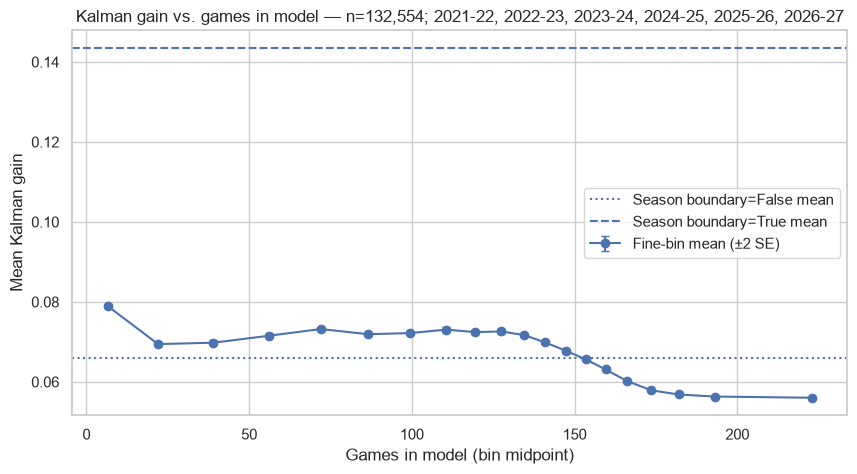

Unexplained positive non-boundary gain jumps:


,games_quantile,n,games_min,games_max,mean_gain,gain_sd,gain_se,season_boundary_n,non_boundary_n,non_boundary_mean_gain,non_boundary_gain_se,gain_jump,gain_jump_se,unexplained_jump_flag
3,3,6679,48,64,0.071525,0.023117,0.000283,218,6461,0.069061,0.000237,0.001512,0.000335,True
4,4,6562,65,79,0.073202,0.023249,0.000287,229,6333,0.070671,0.000244,0.001610,0.000340,True
7,7,6806,106,115,0.073057,0.022913,0.000278,240,6566,0.070540,0.000236,0.000886,0.000332,True


Posterior-draw diagnostics: {'status': 'skipped', 'reason': 'posterior draws unavailable'}


In [7]:
gain_by_tier, gain_by_games, gain_by_boundary = gain_summary(trace)
print("Kalman gain by broad experience tier:")
display(gain_by_tier)
print("Kalman gain by fine games-in-model bins:")
display(gain_by_games)
print("Kalman gain by season-boundary status:")
display(gain_by_boundary)

fig, ax = plt.subplots(figsize=(10, 5))
x = (gain_by_games["games_min"] + gain_by_games["games_max"]) / 2
ax.errorbar(x, gain_by_games["mean_gain"], yerr=2 * gain_by_games["gain_se"], marker="o", capsize=3, label="Fine-bin mean (±2 SE)")
for row in gain_by_boundary.itertuples(index=False):
    ax.axhline(row.mean_gain, linestyle="--" if row.season_boundary else ":", label=f"Season boundary={row.season_boundary} mean")
ax.set(
    title=f"Kalman gain vs. games in model — n={len(trace):,}; {', '.join(evaluation_seasons)}",
    xlabel="Games in model (bin midpoint)",
    ylabel="Mean Kalman gain",
)
ax.legend()
plt.show()

unexplained_jumps = gain_by_games.loc[gain_by_games["unexplained_jump_flag"]]
print("Unexplained positive non-boundary gain jumps:")
if unexplained_jumps.empty:
    print("None")
else:
    display(unexplained_jumps)

draw_report = posterior_draw_summary(trace, draws=None)
print("Posterior-draw diagnostics:", draw_report)

In [8]:
interpretation_lines = ["Diagnostic interpretation and follow-up:"]

for group_column, report in group_reports.items():
    flagged = report.loc[report["actionable_flag"]]
    labels = flagged[group_column].astype(str).tolist()
    preview = ", ".join(labels[:5])
    remainder = len(labels) - min(len(labels), 5)
    preview_text = (
        f"; first flags: {preview}" + (f" (+{remainder} more)" if remainder else "")
        if preview
        else ""
    )
    interpretation_lines.append(
        f"- {group_column}: {len(flagged)} actionable calibration flag(s){preview_text}."
    )

for flag_column, label in (("new_team_flag", "New-team"), ("rookie_flag", "Rookie")):
    report = slice_reports[flag_column]
    flagged_slice = report.loc[report[flag_column] & report["actionable_flag"]]
    true_slice = report.loc[report[flag_column]]
    if true_slice.empty:
        interpretation_lines.append(f"- {label}: no evaluated rows were available.")
    else:
        row = true_slice.iloc[0]
        flag_status = "actionable calibration flag" if not flagged_slice.empty else "no actionable calibration flag"
        interpretation_lines.append(
            f"- {label}: {flag_status}; n={int(row['n']):,}, "
            f"mean z={row['mean_z']:.3f}, SD z={row['sd_z']:.3f}."
        )

slope = float(innovation_state_relationship["slope"])
p_value = float(innovation_state_relationship["p_value"])
if np.isfinite(slope) and np.isfinite(p_value):
    relationship_label = "mean-reversion signal" if slope < 0 else "same-direction signal"
    significance_label = "statistically resolved" if p_value < 0.05 else "not statistically resolved"
    interpretation_lines.append(
        f"- Early-season state/innovation relationship: {relationship_label}; "
        f"slope={slope:.3f}, p={p_value:.3g} ({significance_label})."
    )
else:
    interpretation_lines.append("- Early-season state/innovation relationship: insufficient variation for inference.")

if unexplained_jumps.empty:
    interpretation_lines.append("- Non-boundary gain jumps: none exceeded the diagnostic threshold.")
else:
    jump_bins = ", ".join(
        f"{int(row.games_min)}-{int(row.games_max)} games"
        for row in unexplained_jumps.itertuples(index=False)
    )
    interpretation_lines.append(
        f"- Non-boundary gain jumps: {len(unexplained_jumps)} flagged bin(s) ({jump_bins}); investigate before operational use."
    )

interpretation_lines.append(
    "These diagnostics identify follow-up checks only; they do not constitute deployment approval."
)
print("\n".join(interpretation_lines))

Diagnostic interpretation and follow-up:
- opp_team_id: 28 actionable calibration flag(s); first flags: 1610612757, 1610612764, 1610612762, 1610612740, 1610612747 (+23 more).
- team_id: 20 actionable calibration flag(s); first flags: 1610612760, 1610612759, 1610612749, 1610612753, 1610612764 (+15 more).
- position: 5 actionable calibration flag(s); first flags: C, SF, PF, PG, UNK.
- New-team: actionable calibration flag; n=1,265, mean z=-0.231, SD z=0.907.
- Rookie: actionable calibration flag; n=16,090, mean z=-0.064, SD z=0.880.
- Early-season state/innovation relationship: mean-reversion signal; slope=-0.063, p=6.14e-23 (statistically resolved).
- Non-boundary gain jumps: 3 flagged bin(s) (48-64 games, 65-79 games, 106-115 games); investigate before operational use.
These diagnostics identify follow-up checks only; they do not constitute deployment approval.


## Latest-season live-state monitoring

This section uses the latest two complete prior seasons as the training window and processes the latest available season sequentially with the same causal API. The table is a snapshot of each player's state after their most recently observed game. It is **monitoring, not a future-game forecast**: there is no future schedule, opponent, or role row from which to construct a pregame prediction.

In [9]:
latest_season = available_seasons[-1]
prior_seasons = available_seasons[:-1]
if len(prior_seasons) < CONFIG.train_window_seasons:
    raise ValueError("latest-season monitoring needs two complete prior seasons")
live_training_seasons = tuple(prior_seasons[-CONFIG.train_window_seasons :])
live_seasons = (*live_training_seasons, latest_season)
live_frame = causal.loc[causal["season_year"].astype(str).isin(live_seasons)].copy()
live_trace, live_fold_audits = walk_forward_trace(
    live_frame,
    evaluation_seasons=(latest_season,),
    config=CONFIG,
)
print(
    f"Live-state window: train on {', '.join(live_training_seasons)}; "
    f"causally monitor {latest_season}."
)
print("Latest-season fold audit:")
display(pd.DataFrame(live_fold_audits))

if live_trace.empty:
    raise AssertionError("latest-season live-state trace must not be empty")
latest_rows = (
    live_trace.sort_values(["player_id", "game_date", "game_id"], kind="mergesort")
    .groupby("player_id", sort=False, as_index=False)
    .tail(1)
    .copy()
)
latest_rows["state_sd_after"] = np.sqrt(latest_rows["state_var_after"])
latest_rows["games_in_model"] = latest_rows["games_in_model_before"] + 1
monitoring_columns = [
    "player_name",
    "player_id",
    "team_id",
    "game_date",
    "state_after",
    "state_sd_after",
    "games_in_model",
    "predictive_mean",
    "points",
    "innovation",
    "z",
    "pit",
    "kalman_gain",
]
latest_state_monitoring = latest_rows.loc[:, monitoring_columns].sort_values(
    ["state_after", "player_name"], ascending=[False, True], kind="mergesort"
)
if not np.isfinite(latest_state_monitoring.select_dtypes(include="number").to_numpy(dtype=float)).all():
    raise AssertionError("latest-season monitoring diagnostics must be finite")
print(
    f"Latest-season state monitoring (n={len(latest_state_monitoring):,} players). "
    "Observed-state snapshot; not a future-game forecast."
)
display(latest_state_monitoring.reset_index(drop=True))

Live-state window: train on 2024-25, 2025-26; causally monitor 2026-27.
Latest-season fold audit:


,train_seasons,evaluation_season,candidate_rows,fitted_rows,zero_minute_rows_removed,imputed_feature_cells,predicted_rows,evaluation_imputed_feature_cells,evaluation_rows_with_imputation
0,"(2024-25, 2025-26)",2026-27,52952,52952,0,1778,1275,558,417


Latest-season state monitoring (n=417 players). Observed-state snapshot; not a future-game forecast.


,player_name,player_id,team_id,game_date,state_after,state_sd_after,games_in_model,predictive_mean,points,innovation,z,pit,kalman_gain
0,Luka Dončić,1629029,1610612747,2026-10-27,18.593063,1.978583,118,36.430512,41.0,4.569488,0.708110,0.760560,0.105045
1,Anthony Edwards,1630162,1610612750,2026-10-26,16.917540,1.978632,144,26.283241,47.0,20.716759,3.210361,0.999337,0.105050
2,Shai Gilgeous-Alexander,1628983,1610612760,2026-10-26,13.570383,1.978539,148,31.136953,26.0,-5.136953,-0.796049,0.213003,0.105040
3,Giannis Antetokounmpo,203507,1610612748,2026-10-26,13.526737,1.981424,107,25.097223,29.0,3.902777,0.604691,0.727307,0.105346
4,Donovan Mitchell,1628378,1610612739,2026-10-26,12.922468,2.061915,144,25.560305,26.0,0.439695,0.067792,0.527024,0.114079
...,...,...,...,...,...,...,...,...,...,...,...,...,...
412,Josh Okogie,1629006,1610612762,2026-10-26,-4.597984,2.061872,121,3.500655,0.0,-3.500655,-0.539735,0.294691,0.114074
413,Sion James,1642883,1610612766,2026-10-26,-4.612820,1.978472,86,4.570822,5.0,0.429178,0.066508,0.526513,0.105033
414,Drake Powell,1642962,1610612751,2026-10-25,-4.642985,2.285843,64,8.236551,0.0,-8.236551,-1.251053,0.105460,0.140203
415,Tyus Jones,1626145,1610612743,2026-10-26,-5.007838,2.061944,151,2.634948,0.0,-2.634948,-0.406257,0.342278,0.114082
